In [1]:
from google.colab import drive
drive.mount('/content/drive')

import zipfile
zip_path = "/content/drive/MyDrive/kvasir-seg.zip"
extract_path = "/content/kvasir-seg"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print(" Dataset extracted at:", extract_path)

Mounted at /content/drive
 Dataset extracted at: /content/kvasir-seg


In [2]:
!pip install segmentation-models-pytorch --quiet
!pip install albumentations --quiet

In [3]:
import random
import torch
import torch.nn as nn
import segmentation_models_pytorch as smp
import albumentations as A
from albumentations.pytorch import ToTensorV2
from glob import glob
import numpy as np
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
import cv2
from tqdm import tqdm

# Seed
random.seed(44); np.random.seed(44)
torch.manual_seed(44); torch.cuda.manual_seed_all(44)

# Paths
image_dir = "/content/kvasir-seg/Kvasir-SEG/images/"
mask_dir = "/content/kvasir-seg/Kvasir-SEG/masks/"
images = sorted(glob(image_dir + "*.jpg"))
masks = sorted(glob(mask_dir + "*.jpg"))

# Train-Validation Split
train_imgs, val_imgs, train_masks, val_masks = train_test_split(images, masks, test_size=0.2, random_state=42)

# Dataset (returns image, mask and edge map)
class PolypDataset(Dataset):
    def __init__(self, images, masks, augment=None):
        self.images = images
        self.masks = masks
        self.augment = augment

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = cv2.imread(self.images[idx])
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        mask = cv2.imread(self.masks[idx], cv2.IMREAD_GRAYSCALE)
        mask = (mask > 127).astype(np.float32)

        if self.augment:
            augmented = self.augment(image=img, mask=mask)
            img, mask = augmented['image'].float(), augmented['mask'].unsqueeze(0).float()

        # Edge map from the mask (Canny)
        m = (mask[0].numpy() * 255).astype(np.uint8)
        edge = cv2.Canny(m, 100, 200) / 255.0
        edge = torch.tensor(edge, dtype=torch.float32).unsqueeze(0)
        return img, mask, edge

# Augmentations
train_aug = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomBrightnessContrast(p=0.5),
    A.HueSaturationValue(p=0.5),
    A.ElasticTransform(p=0.3),
    A.CLAHE(p=0.2),
    A.Resize(256, 256),
    ToTensorV2()
])

val_aug = A.Compose([
    A.Resize(256, 256),
    ToTensorV2()
])

# Loaders
train_dataset = PolypDataset(train_imgs, train_masks, train_aug)
val_dataset = PolypDataset(val_imgs, val_masks, val_aug)
train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=4, shuffle=False, num_workers=2)

# Model: EfficientNet-B3 + scSE, 2 outputs (channel 0 = mask, channel 1 = edge)
model = smp.Unet(
    encoder_name="efficientnet-b3",
    encoder_weights="imagenet",
    in_channels=3,
    classes=2,
    activation=None,
    encoder_depth=5,
    decoder_attention_type="scse"
).cuda()

# Losses
class DiceLoss(nn.Module):
    def forward(self, inputs, targets, smooth=1):
        inputs = torch.sigmoid(inputs)
        inputs = inputs.view(-1)
        targets = targets.view(-1)
        intersection = (inputs * targets).sum()
        dice = (2. * intersection + smooth) / (inputs.sum() + targets.sum() + smooth)
        return 1 - dice

class FocalTverskyLoss(nn.Module):
    def __init__(self, alpha=0.7, beta=0.3, gamma=0.75):
        super().__init__()
        self.alpha = alpha
        self.beta = beta
        self.gamma = gamma
    def forward(self, inputs, targets, smooth=1):
        inputs = torch.sigmoid(inputs)
        inputs = inputs.view(-1)
        targets = targets.view(-1)
        TP = (inputs * targets).sum()
        FP = ((1 - targets) * inputs).sum()
        FN = (targets * (1 - inputs)).sum()
        tversky = (TP + smooth) / (TP + self.alpha*FP + self.beta*FN + smooth)
        return (1 - tversky) ** self.gamma

bce_loss = nn.BCEWithLogitsLoss()
dice_loss = DiceLoss()
focal_tversky = FocalTverskyLoss()

def hybrid_loss(pred, target):
    return 0.4*bce_loss(pred, target) + 0.4*dice_loss(pred, target) + 0.2*focal_tversky(pred, target)

def edge_loss(pred, target):
    return bce_loss(pred, target) + dice_loss(pred, target)

def total_loss(out, mask, edge):
    return hybrid_loss(out[:, 0:1], mask) + 0.3 * edge_loss(out[:, 1:2], edge)

# Optimizer & Scheduler
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(optimizer, T_0=5, T_mult=2)

# Mixed Precision
scaler = torch.cuda.amp.GradScaler()

# Training Loop
for epoch in range(25):
    model.train()
    train_loss = 0
    for imgs, masks, edges in tqdm(train_loader, desc=f"Epoch {epoch+1}/25 - Train"):
        imgs, masks, edges = imgs.cuda(), masks.cuda(), edges.cuda()
        optimizer.zero_grad()
        with torch.cuda.amp.autocast():
            outputs = model(imgs)
            loss = total_loss(outputs, masks, edges)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        train_loss += loss.item()
    scheduler.step()
    print(f"Epoch {epoch+1} | Train Loss: {train_loss/len(train_loader):.4f}")

    # Validation
    model.eval()
    dices = []
    with torch.no_grad():
        for imgs, masks, edges in tqdm(val_loader, desc="Validating"):
            imgs, masks = imgs.cuda(), masks.cuda()
            outputs = torch.sigmoid(model(imgs)[:, 0:1])
            preds = (outputs > 0.5).float()
            intersection = (preds * masks).sum(dim=(1,2,3))
            union = preds.sum(dim=(1,2,3)) + masks.sum(dim=(1,2,3))
            dice = (2*intersection) / (union + 1e-8)
            dices.extend(dice.cpu().numpy())
    print(f"Val Dice: {np.mean(dices):.4f}")

# Save model and parameter count
torch.save(model.state_dict(), "/content/drive/MyDrive/eae_edge_effb3_kvasir.pth")
print("Params:", sum(p.numel() for p in model.parameters()))

config.json:   0%|          | 0.00/106 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 49.3MB            

model.safetensors: downloading bytes:           |  0.00B            

/tmp/ipykernel_2306/161976710.py:131: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
Epoch 1/25 - Train:   0%|          | 0/100 [00:00<?, ?it/s]/tmp/ipykernel_2306/161976710.py:140: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
Epoch 1/25 - Train: 100%|██████████| 100/100 [00:50<00:00,  1.99it/s]


Epoch 1 | Train Loss: 1.1635


Validating: 100%|██████████| 50/50 [00:02<00:00, 20.54it/s]


... (93 outputs left out)

Epoch 25/25 - Train: 100%|██████████| 100/100 [00:41<00:00,  2.43it/s]


Epoch 25 | Train Loss: 0.2810


Validating: 100%|██████████| 50/50 [00:02<00:00, 21.76it/s]


Val Dice: 0.8871
Params: 13222840


In [4]:
import numpy as np, torch, pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score
from tqdm import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
model.eval()

def dice_coef(t, p, s=1e-7):
    t, p = t.view(-1), p.view(-1)
    return ((2. * (t * p).sum() + s) / (t.sum() + p.sum() + s)).item()

def iou_score(t, p, s=1e-7):
    t, p = t.view(-1), p.view(-1)
    inter = (t * p).sum()
    return ((inter + s) / (t.sum() + p.sum() - inter + s)).item()

dice, iou, prec, rec, f1, acc = [], [], [], [], [], []

with torch.no_grad():
    for imgs, masks, edges in tqdm(val_loader, desc="Metrics"):
        imgs, masks = imgs.to(device), masks.to(device)
        preds = (torch.sigmoid(model(imgs)[:, 0:1]) > 0.5).float()
        for i in range(imgs.size(0)):
            dice.append(dice_coef(masks[i], preds[i]))
            iou.append(iou_score(masks[i], preds[i]))
            yt = masks[i].cpu().numpy().astype(np.uint8).flatten()
            yp = preds[i].cpu().numpy().astype(np.uint8).flatten()
            prec.append(precision_score(yt, yp, zero_division=0))
            rec.append(recall_score(yt, yp, zero_division=0))
            f1.append(f1_score(yt, yp, zero_division=0))
            acc.append(accuracy_score(yt, yp))

metrics_df = pd.DataFrame({
    "Dice": [np.mean(dice)], "IoU": [np.mean(iou)],
    "Precision": [np.mean(prec)], "Recall": [np.mean(rec)],
    "F1-score": [np.mean(f1)], "Accuracy": [np.mean(acc)]
})
print(metrics_df)
metrics_df.to_csv("/content/drive/MyDrive/edge_effb3_metrics.csv", index=False)

Metrics: 100%|██████████| 50/50 [00:22<00:00,  2.24it/s]


       Dice       IoU  Precision   Recall  F1-score  Accuracy
0  0.887121  0.825724   0.921061  0.87586  0.887121  0.971983


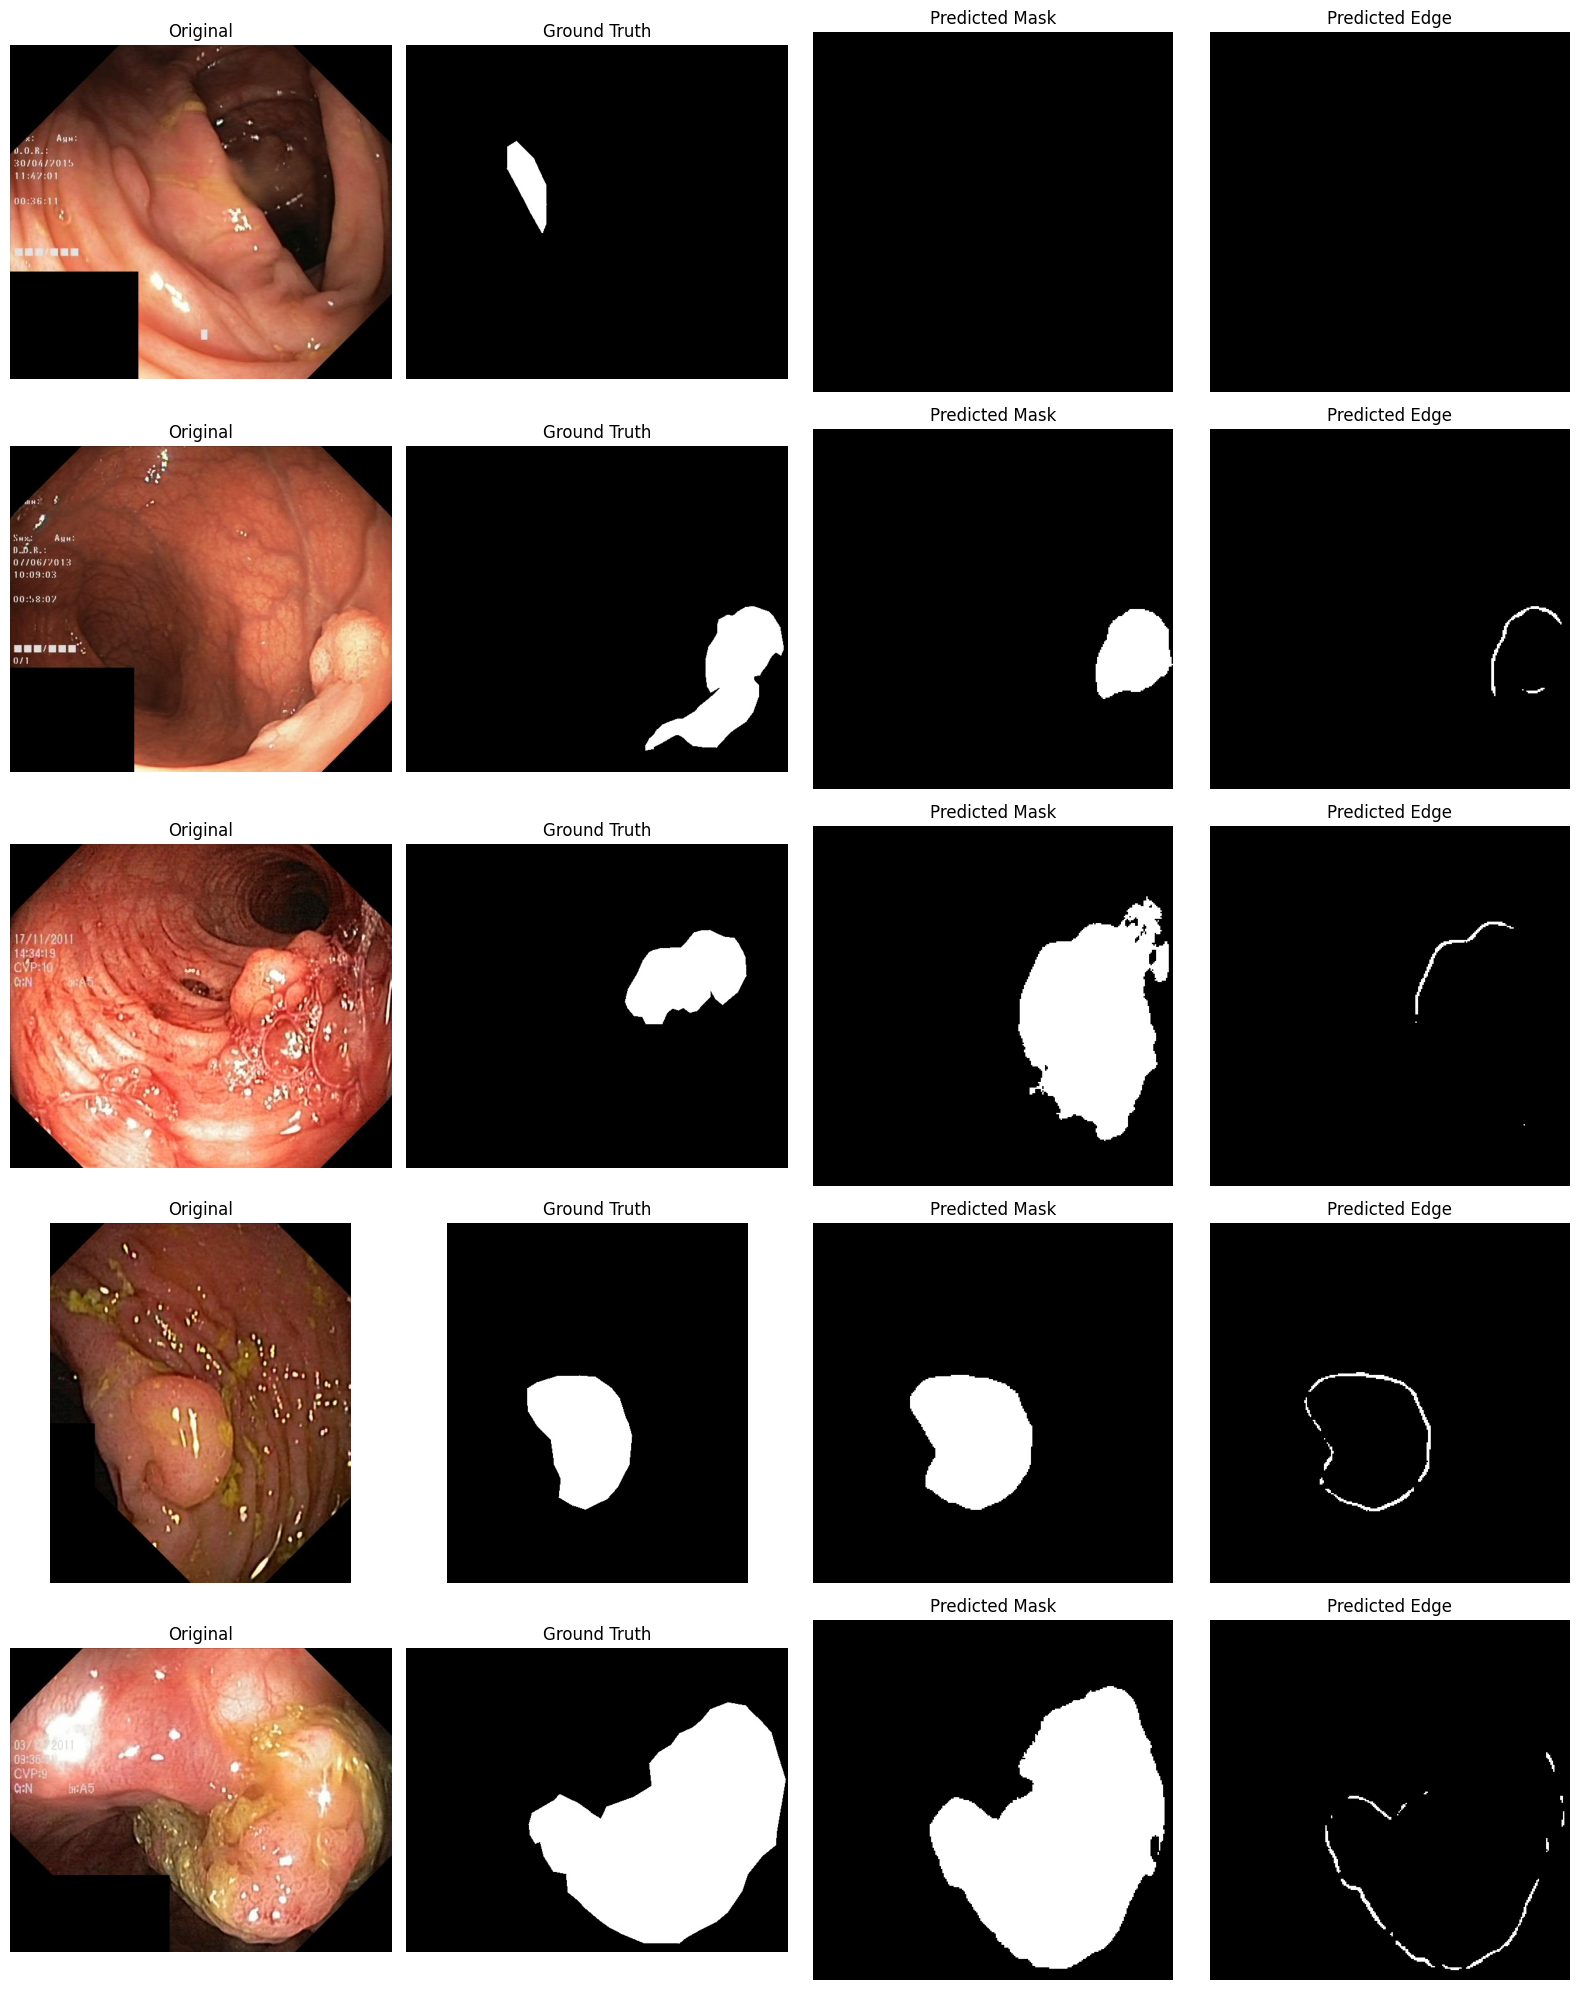

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:
import random, cv2, torch
import matplotlib.pyplot as plt
from google.colab import files

model.eval()
idxs = random.sample(range(len(val_dataset)), k=5)
fig = plt.figure(figsize=(16, 4 * len(idxs)))

for n, k in enumerate(idxs):
    img = cv2.cvtColor(cv2.imread(val_dataset.images[k]), cv2.COLOR_BGR2RGB)
    gt = cv2.imread(val_dataset.masks[k], cv2.IMREAD_GRAYSCALE)
    x, _, _ = val_dataset[k]
    with torch.no_grad():
        out = torch.sigmoid(model(x.unsqueeze(0).to(device)))[0].cpu().numpy()

    items = [(img, "Original", None),
             (gt, "Ground Truth", "gray"),
             ((out[0] > 0.5).astype(float), "Predicted Mask", "gray"),
             ((out[1] > 0.5).astype(float), "Predicted Edge", "gray")]
    for j, (im, title, cm) in enumerate(items):
        ax = fig.add_subplot(len(idxs), 4, n * 4 + j + 1)
        ax.imshow(im, cmap=cm)
        ax.set_title(title)
        ax.axis("off")

plt.tight_layout()
fig.savefig("edge_original_gt_pred.png", bbox_inches="tight", dpi=200)
plt.show()
files.download("edge_original_gt_pred.png")